In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler


In [4]:
from google.colab import files
uploaded=files.upload()


Saving Titanic-Dataset.csv to Titanic-Dataset.csv


In [7]:
df=pd.read_csv("Titanic-Dataset.csv")
df.head()
df.shape

(891, 12)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [10]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [11]:
df['Age']=df['Age'].fillna(df['Age'].mean())
df['Age']=df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df = df.drop('Cabin', axis=1)
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [12]:
df.select_dtypes(include=['object']).columns

Index(['Name', 'Sex', 'Ticket', 'Embarked'], dtype='object')

In [13]:
df=df.drop(['Name','Ticket'],axis=1)

In [14]:
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

In [15]:
df = pd.get_dummies(df, columns=['Embarked'], drop_first=True)

In [16]:
df.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,1,0,3,0,22.0,1,0,7.2500,False,True
1,2,1,1,1,38.0,1,0,71.2833,False,False
2,3,1,3,1,26.0,0,0,7.9250,False,True
3,4,1,1,1,35.0,1,0,53.1000,False,True
4,5,0,3,0,35.0,0,0,8.0500,False,True


In [18]:
df.dtypes
df=df.astype(int)

In [19]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Sex,int64
Age,int64
SibSp,int64
Parch,int64
Fare,int64
Embarked_Q,int64
Embarked_S,int64


In [20]:
numerical_features = ['Age', 'Fare', 'SibSp', 'Parch', 'Pclass']

In [21]:
scaler=StandardScaler()
df[numerical_features]=scaler.fit_transform(df[numerical_features])

In [22]:
df.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,1,0,0.827377,0,-0.580044,0.432793,-0.473674,-0.498948,0,1
1,2,1,-1.566107,1,0.650112,0.432793,-0.473674,0.789405,0,0
2,3,1,0.827377,1,-0.272505,-0.474545,-0.473674,-0.498948,0,1
3,4,1,-1.566107,1,0.419458,0.432793,-0.473674,0.427056,0,1
4,5,0,0.827377,0,0.419458,-0.474545,-0.473674,-0.478817,0,1


In [23]:
df[numerical_features].mean()

,0
Age,-7.974666e-18
Fare,3.787966e-17
SibSp,4.386066e-17
Parch,5.382900e-17
Pclass,-8.772133e-17


In [24]:
df[numerical_features].std()

,0
Age,1.000562
Fare,1.000562
SibSp,1.000562
Parch,1.000562
Pclass,1.000562


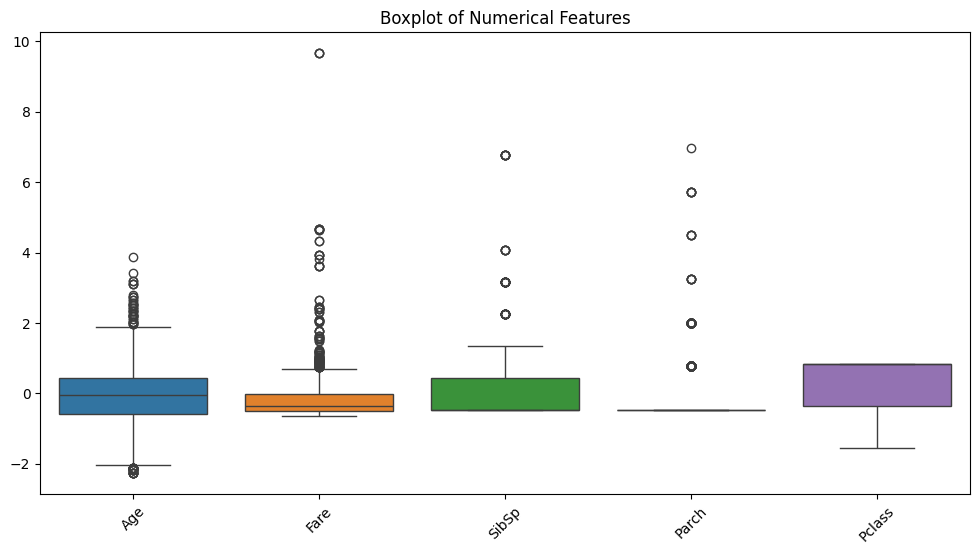

In [25]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[numerical_features])

plt.xticks(rotation=45)
plt.title("Boxplot of Numerical Features")
plt.show()

In [26]:
for column in numerical_features:
  Q1=df[column].quantile(0.25)
  Q3=df[column].quantile(0.75)
  IQR=Q3-Q1
  lower_bound=Q1-1.5*IQR
  upper_bound=Q3+1.5*IQR

  outliers=df[(df[column]<lower_bound) | (df[column]>upper_bound)]
  print(column, ":", len(outliers), "outliers")


Age : 66 outliers
Fare : 114 outliers
SibSp : 46 outliers
Parch : 213 outliers
Pclass : 0 outliers


In [27]:
for column in numerical_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df = df[(df[column] >= lower_bound) &
            (df[column] <= upper_bound)]

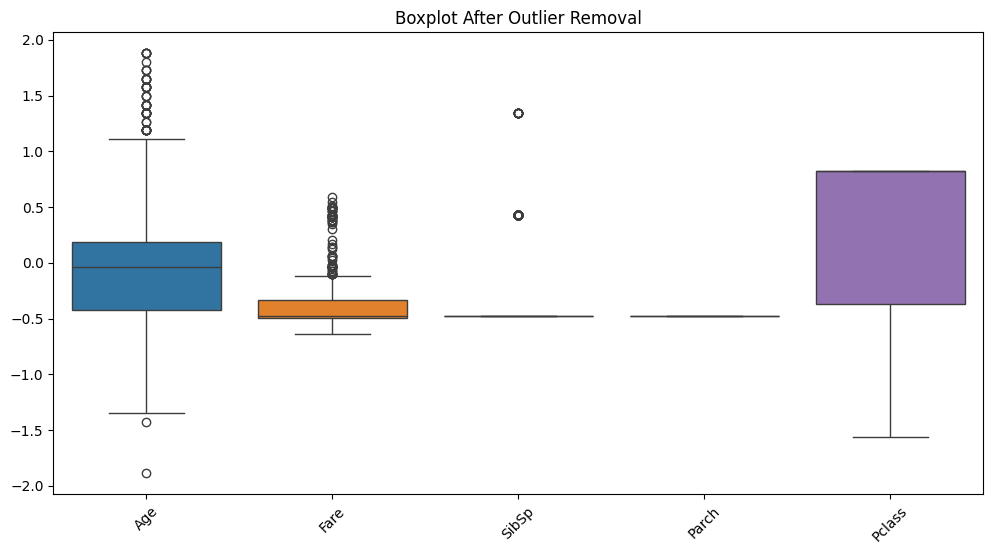

In [28]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[numerical_features])

plt.xticks(rotation=45)
plt.title("Boxplot After Outlier Removal")
plt.show()

In [32]:
print(df.shape)
df.head()
df.isnull().sum()
df.info()

(577, 10)
<class 'pandas.core.frame.DataFrame'>
Index: 577 entries, 0 to 890
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  577 non-null    int64  
 1   Survived     577 non-null    int64  
 2   Pclass       577 non-null    float64
 3   Sex          577 non-null    int64  
 4   Age          577 non-null    float64
 5   SibSp        577 non-null    float64
 6   Parch        577 non-null    float64
 7   Fare         577 non-null    float64
 8   Embarked_Q   577 non-null    int64  
 9   Embarked_S   577 non-null    int64  
dtypes: float64(5), int64(5)
memory usage: 49.6 KB
